# Exploración reproducible: `sms_spam_5971`

Este notebook lee el CSV original sin modificarlo. El análisis completo se guarda en [`../reports/sms_spam_5971.md`](../reports/sms_spam_5971.md).

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
while not (HERE / 'notebooks' / 'exploracion-datasets' / 'dataset_audit.py').exists():
    if HERE.parent == HERE:
        raise FileNotFoundError('No se encontró la raíz del repositorio')
    HERE = HERE.parent
sys.path.insert(0, str(HERE / 'notebooks' / 'exploracion-datasets'))
from dataset_audit import DATASETS, analyze_dataset, load_dataset, combined_text
spec = next(item for item in DATASETS if item.slug == 'sms_spam_5971')
df = load_dataset(spec)
result = analyze_dataset(spec)
print(f'Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas')
print(f'Objetivo: {spec.target}')

Dimensiones: 5,971 filas × 5 columnas
Objetivo: LABEL


## Esquema, tipos y nulos

In [2]:
schema = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'nulos': df.isna().sum(),
    'nulos_pct': (df.isna().mean() * 100).round(2),
})
display(schema)

,tipo,nulos,nulos_pct
LABEL,str,0,0.0
TEXT,str,0,0.0
URL,str,0,0.0
EMAIL,str,0,0.0
PHONE,str,0,0.0


## Clases, duplicados y conflictos

,registros
LABEL,
ham,4844
Smishing,616
spam,466
Spam,23
smishing,22


Filas duplicadas: 17
Filas con texto repetido: 273
Textos con etiquetas conflictivas: 49


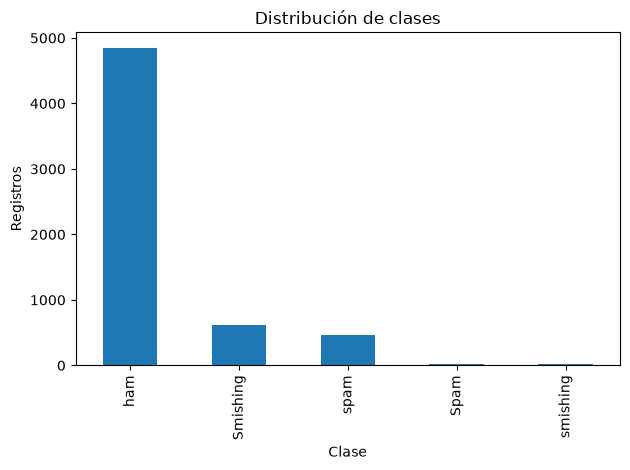

In [3]:
display(df[spec.target].value_counts(dropna=False).rename('registros').to_frame())
print('Filas duplicadas:', result['full_row_duplicates'])
print('Filas con texto repetido:', result['text_duplicates'])
print('Textos con etiquetas conflictivas:', result['conflicting_normalized_texts'])
df[spec.target].astype(str).value_counts().plot(kind='bar', title='Distribución de clases')
plt.xlabel('Clase'); plt.ylabel('Registros'); plt.tight_layout(); plt.show()

## Longitud, idioma y patrones

,caracteres,palabras
count,5971.000000,5971.000000
min,2.000000,0.000000
q25,38.000000,8.000000
median,66.000000,13.000000
mean,83.197119,15.948752
q75,127.000000,23.000000
p95,161.000000,32.000000
max,910.000000,190.000000


Idiomas declarados o estimados: {'en': 3253, 'indeterminado': 2716, 'es': 2}
Filas con URL/correo/teléfono: 183 22 709


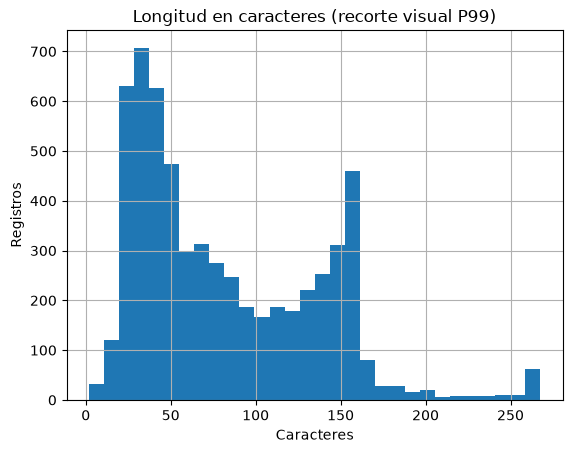

In [4]:
display(pd.DataFrame({
    'caracteres': result['length_characters'],
    'palabras': result['length_words'],
}))
print('Idiomas declarados o estimados:', result['declared_languages'] or result['language_heuristic'])
print('Filas con URL/correo/teléfono:', result['rows_with_url_pattern'], result['rows_with_email_pattern'], result['rows_with_phone_pattern'])
text = combined_text(df, spec.text_columns)
text.str.len().clip(upper=text.str.len().quantile(.99)).hist(bins=30)
plt.title('Longitud en caracteres (recorte visual P99)'); plt.xlabel('Caracteres'); plt.ylabel('Registros'); plt.show()

## Ejemplos sanitizados y conclusión

In [5]:
for label, examples in result['examples'].items():
    print(f'\nClase {label}')
    for example in examples:
        print('-', example)


Clase Smishing
- FreeMsg Why haven't you replied to my text? I'm female and live local. Luv to hear from u. Netcollex Ltd 08700621170150p per msg reply Stop to end
- SMS. ac Blind Date 4U!: Rodds1 is 21/m from Aberdeen, United Kingdom. Check Him out hxxp://img. sms. ac/W/icmb3cktz8r7!-4 no Blind Dates send HIDE

Clase Spam
- -PLS STOP bootydelious (32/F) is inviting you to be her friend. Reply YES-434 or NO-434 See her: www.SMS.ac/u/bootydelious STOP? Send STOP FRND to 62468
- Property Bhi Aapki Rent Bhi Aapka, Invest Rs 17k Lacs in Fully Furnished Office Spaces & Earn Rs 17k per Month Wid Bank Guarantee, Noida Cont.[telefono-oculto]

Clase ham
- Gud ni8 dear..slp well..take care..swt dreams..Muah..
- Yupz... I've oredi booked slots 4 my weekends liao...

Clase smishing
- WIN: We have a winner! Mr. T. Tilo won an iPod! More exciting prizes soon, so keep an eye on ur mobile or visit www.win-82050.co.uk
- Loan INR5,00,000 - 7,50,000. Homeowners + Tenants welcome. Have you been previousl

La interpretación, riesgos de fuga, sesgos, utilidad para Random Forest y estrategia de combinación están documentados en [`../reports/sms_spam_5971.md`](../reports/sms_spam_5971.md).